In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

from pprint import pprint
import pickle

from functools import partial

import numpy as np
from sklearn.preprocessing import scale
from sklearn.decomposition import PCA
# import sklearn.metrics as metrics
from sklearn.metrics import accuracy_score

import matplotlib.pyplot as plt
import matplotlib.animation as ani

import mlgrad.models as models
import mlgrad.regr as regr
import mlgrad.cls as cls
import mlgrad.pca as pca
import mlgrad.plots as plots
import mlgrad.funcs as funcs
import mlgrad.funcs2 as funcs2
import mlgrad.loss as loss
import mlgrad.gd as gd
import mlgrad.smooth as smooth
import mlgrad.inventory as inventory
from mlgrad.af import averaging_function

import rampy
import pybaselines
import random

from irsa import io
from irsa.preprocess import despike, utils
import irsa.widgets as widgets
import irsa.spectra as spectra
import irsa.io as io

import scipy.special as special

import copy

import ipywidgets
from IPython.display import display

import sys
print(sys.version)

# %matplotlib widget

3.14.8 (main, Oct  1 2026, 19:55:55) [GCC 16.2.0]


In [2]:
def plot_params(lfm, p_threshold=1.0e-4):
    ax = plt.twinx(plt.gca())
    n = lfm.n_input
    mask = np.zeros(n, np.uint8)
    for mod in lfm.models:
        param1 = np.asarray(mod.param[1:])
        # print(param1[0])
        param_p = param1.copy()
        param_m = param1.copy()
        param_p[param1 < 0] = 0
        param_m[param1 > 0] = 0
        mask = mask | (abs(param1) > p_threshold)
        ax.vlines(range(mod.n_input), param_m, param_p, color='k')
    ax.minorticks_on()
    s = mask.astype("i").sum()
    plt.title(f'Значения коэффициентов классификатора:  #(abs(param) > {p_threshold}) = {s}')

def plot_param(param, p_threshold=1.0e-4):
    ax = plt.twinx(plt.gca())
    n = len(param)
    param_p = param.copy()
    param_m = param.copy()
    param_p[param < 0] = 0
    param_m[param > 0] = 0
    ax.vlines(range(n), param_m, param_p, color='k')
    ax.minorticks_on()
    if p_threshold != 0:
        mask = (abs(param) > p_threshold)
        s = mask.astype("i").sum()
        plt.title(f'#(abs(param) > {p_threshold}) = {s}')

In [3]:
def rescale_by(X, Y):
    mu_y = np.median(Y, axis=0)
    sigma_y = np.median(abs(Y - mu_y))
    mu_x = np.median(X, axis=0)
    sigma_x = np.median(abs(X - mu_x))
    return (X - mu_x) / sigma_x * sigma_y + mu_y
    

In [4]:
def plot_pca(xs, Ys, labels, colors=None, markers=None, kind="l2/l2", 
             q=1.0, m=5, mm=3, n_iter=200, tol=1.0e-6, verbose=False, 
             plot_reconstructed=False, plot_eigenval=False, plot_eigenvec=False,
             return_result=False):

    Y = np.vstack(Ys)
    c, As, Ls = pca.find_loc_pc_sv(Y, m, n_iter=n_iter, tol=tol, verbose=verbose, q=q)
    Us = [pca.transform(ys, c, As) for ys in Ys]

    plt.figure(figsize=(15,5))
    for i in range(mm):
        plt.subplot(1,mm,i+1)
        if colors is None:
            for U, label in zip(Us, labels):
                plt.scatter(U[:,i], U[:,i+1], s=25, edgecolors='k', linewidth=0.5, label=label)
        else:
            if markers is None:
                for U, label, color in zip(Us, labels, colors):
                    plt.scatter(U[:,i], U[:,i+1], s=25, c=color, edgecolors='k', linewidth=0.5, label=label)
            else:
                for U, label, color, marker in zip(Us, labels, colors, markers):
                    plt.scatter(U[:,i], U[:,i+1], s=25, c=color, marker=marker, edgecolors='k', linewidth=0.5, label=label)
        plt.xlabel(str(i+1))
        plt.ylabel(str(i+2))
        plt.legend()
    plt.tight_layout()
    plt.legend()
    plt.show()

    if plot_reconstructed:
        plt.figure(figsize=(12,5))
        plt.title("Reconstruction from PCs")
        for U, label in zip(Us, labels):
            plt.plot(xs, (U @ As + c).mean(axis=0), label=label)
        plt.tight_layout()
        plt.minorticks_on()
        plt.legend()
        plt.show()

    Ls /= Ls.sum()

    if plot_eigenvec:
        plt.figure(figsize=(12,6))
        for i,a in enumerate(As[:10]):
            plt.plot(xs, a*Ls[i], label=str(i+1))
        plt.ylabel("PCs")
        plt.legend()
    
        plt.minorticks_on()
        plt.grid(lw=0.5, ls=':')
        plt.tight_layout()
        plt.show()
    
    if plot_eigenval:
        plt.figure(figsize=(10,3))
        plt.title("Собственные числа")
        plt.plot(Ls, marker='o', ms=2)
        plt.yscale('log')
        plt.xscale('log')
        plt.grid(ls=':', lw=0.5)
        plt.ylabel(r"$\log\lambda$")
        plt.minorticks_on()
        plt.show()

    if return_result:
        return c, As


In [5]:
def plot_pca_raw(Ys):
    c, As, Ls = pca.find_loc_and_pc(Ys, 10)
    U = (Ys - c) @ As.T
    plt.figure(figsize=(15,4))
    for i in range(4):
        plt.subplot(1,4,i+1)
        plt.scatter(U[:,i], U[:,i+1], s=25, c='r', edgecolors='k', linewidth=0.5, label="Raw")
        plt.xlabel(f"PC {str(i+1)}")
        plt.ylabel(f"PC {str(i+2)}")
        # plt.xticks([])
        # plt.yticks([])
        plt.legend()
    plt.tight_layout()
    plt.legend()
    plt.show()
    
    plt.figure(figsize=(10,3))
    plt.title("Собственные числа")
    plt.plot(Ls/Ls.sum(), marker='o')
    plt.grid(ls=':', lw=0.5)
    plt.minorticks_on()
    plt.show()

In [6]:
def plot_robust_pca(Ys_SS, Ys_SA, Ys_SH, wma):
    Ys = np.vstack((Ys_SS, Ys_SA, Ys_SH))
    # c = np.zeros_like(Ys[0])
    # As, Ls = pca.find_pc_all(Ys, 5)
    c, As, Ls = pca.find_robust_loc_and_pc(Ys, wma, 10)
    U = pca.transform(Ys, c, As)
    U_SA = pca.transform(Ys_SA, c, As)
    U_SS = pca.transform(Ys_SS, c, As)
    U_SH = pca.transform(Ys_SH, c, As)
    plt.figure(figsize=(15,4))
    for i in range(4):
        plt.subplot(1,4,i+1)
        plt.scatter(U_SA[:,i], U_SA[:,i+1], s=25, c='r', edgecolors='k', linewidth=0.5, label="SA")
        plt.scatter(U_SH[:,i], U_SH[:,i+1], s=25, c='g', edgecolors='k', linewidth=0.5, label="SH")
        plt.scatter(U_SS[:,i], U_SS[:,i+1], s=25, c='b', edgecolors='k', linewidth=0.5, label="SS")
        plt.xlabel(f"PC {str(i+1)}")
        plt.ylabel(f"PC {str(i+2)}")
        # plt.xticks([])
        # plt.yticks([])
        plt.legend()
    plt.tight_layout()
    plt.legend()
    plt.show()

    Ls /= Ls.sum()
    
    plt.figure(figsize=(12,4))
    for i,a in enumerate(As):
        plt.plot(a, label=str(i+1))
    plt.minorticks_on()
    plt.grid(lw=0.5, ls=':')
    plt.legend()
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(10,3))
    plt.title("Собственные числа")
    plt.plot(Ls, marker='o')
    plt.grid(ls=':', lw=0.5)
    plt.minorticks_on()
    plt.show()

In [7]:
def preprocess_step1(dd, msc=True, svd=True):
    print("Step 1")
    dd.crop(400)    
    # dd.despike(3.5)
    if msc:
        dd.multiplicative_scatter_correction()
    dd.drop_notfinite()
    dd.drop_zeros_spectrum()
    dd.drop_empty()
    
    if svd:
        dd.denoise_svd()
    dd.robust_averaging()
    # dd.flatten()
    if msc:
        dd.multiplicative_scatter_correction()
    dd.filter(kind="m-zscore", tau=2.0)

def preprocess_step2(dd, msc=True, svd=True):
    print("Step 2")
    if msc:
        dd.multiplicative_scatter_correction()

    dd.drop_notfinite()
    dd.drop_zeros_spectrum()

    if svd:
        dd.denoise_svd()

    dd.subtract_baselines(tau2=1.0e3, #tau1=-1.0e-4,    
                      func=funcs.RQStep(0, 1.0e-2),
                      func2_e=inventory.relative_abs_max,
                      verbose=False, n_jobs=8, d=2)

    dd.scale_by_mean()
    dd.filter(kind="m-zscore", tau=2.0)


In [8]:
path = f"/home/intellimath/YD/repos/spectra/20"
dd20 = io.load_spectra(path, {
                            "вид_бактерий":["SA", "SS", "SH"], 
                            "номер_цикла":["20"], 
                            "лизис":["термический"],
                            # "номер_эксперимента_в_цикле":["2", "4"],
                            "отсечки_по_молекулярной_массе": ["super"],
                           })


In [9]:
preprocess_step1(dd20)

Step 1


In [10]:
path = f"/home/intellimath/YD/repos/spectra/21_SU"
dd21 = io.load_spectra(path, { #"вид_бактерий":["A", "B", "C", "D"], 
                            # "номер_цикла":["1"], 
                            "лизис":"термический",
                            # "номер_эксперимента_в_цикле":["2", "4"],
                            "отсечки_по_молекулярной_массе": ["super"],                            
                           }, verbose=False)

In [11]:
import pandas as pd
df = pd.read_csv("spectra_21_tab1.csv", sep="\t")
cls_col = df["cls"]
cls_name_col = cls_col.apply(lambda x: x.split("/")[0][:2])
cls_nn_col = cls_col.apply(lambda x: x.split("/")[1])
df.__delitem__("cls")
df["cls_name"] = cls_name_col
df["cls_nn"] = cls_nn_col
id1_array = df["id1"].values
id2_array = df["id2"].values
id_to_cls = {int(id):name.upper() for id,name in zip(id1_array, cls_name_col.values)}

In [12]:
dd1 = spectra.SpectraCollection()
for key in dd21.spectra.keys():
    keys = key.split("_")
    id0 = keys[0]
    id = int(id0[2:])
    keys[1] = id0
    keys[0] = id_to_cls[id].upper()
    new_key = "_".join(keys)
    sp = dd21.spectra[key]
    sp.attrs["key"] = new_key
    sp.attrs["вид_бактерий"] = keys[0]
    sp.attrs["штамм_бактерий"] = keys[1]
    dd1[new_key] = sp
dd21 = dd1
del dd1

In [13]:
preprocess_step1(dd21)

Step 1


In [14]:
path = f"/home/intellimath/YD/repos/spectra/22_SU"
dd22 = io.load_spectra(path, { #"вид_бактерий":["A", "B", "C", "D"], 
                            # "номер_цикла":["1"], 
                            "лизис":"термический",
                            # "номер_эксперимента_в_цикле":["2", "4"],
                            "отсечки_по_молекулярной_массе": ["super"],                            
                           }, verbose=False)

In [15]:
import pandas as pd
df = pd.read_csv("spectra_22_tab1.csv", sep=",")
cls_col = df["cls"]
cls_name_col = cls_col.apply(lambda x: x.split(" ")[0][:2])
cls_nn_col = cls_col.apply(lambda x: x.split(" ")[1])
df.__delitem__("cls")
df["cls_name"] = cls_name_col
df["cls_nn"] = cls_nn_col
id1_array = df["id1"].values
id2_array = df["id2"].values
id_to_cls = {id:name.upper() for id,name in zip(id1_array, cls_name_col.values)}

In [16]:
dd1 = spectra.SpectraCollection()
for key in dd22.spectra.keys():
    keys = key.split("_")
    key0 = keys[0]
    name = id_to_cls[key0]
    keys[1] = key0
    keys[0] = name
    keys[3] = "22"
    new_key = "_".join(keys)
    sp = dd22.spectra[key]
    sp.attrs["key"] = new_key
    sp.attrs["вид_бактерий"] = name
    sp.attrs["штамм_бактерий"] = key0
    dd1[new_key] = sp
    print(new_key)
dd22 = dd1
del dd1

SH_SU10__22_Test__1_термический_20260703_super_SE__H2O(HPLC)_
SH_SU11__22_Test__1_термический_20260706_super_SE__H2O(HPLC)_
SS_SU12__22_Test__1_термический_20260706_super_SE__H2O(HPLC)_
SS_SU13__22_Test__1_термический_20260706_super_SE__H2O(HPLC)_
SA_SU14__22_Test__1_термический_20260706_super_SE__H2O(HPLC)_
SH_SU15__22_Test__1_термический_20260706_super_SE__H2O(HPLC)_
SS_SU16__22_Test__1_термический_20260706_super_SE__H2O(HPLC)_
SH_SU17__22_Test__1_термический_20260706_super_SE__H2O(HPLC)_
SS_SU18__22_Test__1_термический_20260706_super_SE__H2O(HPLC)_
SA_SU19__22_Test__1_термический_20260706_super_SE__H2O(HPLC)_
SS_SU1__22_Test__1_термический_20260703_super_SE__H2O(HPLC)_
SS_SU20__22_Test__1_термический_20260706_super_SE__H2O(HPLC)_
SS_SU3__22_Test__1_термический_20260703_super_SE__H2O(HPLC)_
SH_SU4__22_Test__1_термический_20260703_super_SE__H2O(HPLC)_
SA_SU5__22_Test__1_термический_20260703_super_SE__H2O(HPLC)_
SA_SU6__22_Test__1_термический_20260703_super_SE__H2O(HPLC)_
SS_SU7__22_Te

In [17]:
preprocess_step1(dd22)

Step 1


In [18]:
path = f"/home/intellimath/YD/repos/spectra/23_24"
dd23_24 = io.load_spectra(path, {
                            # "вид_бактерий":["SA", "SS", "SH"], 
                            # "номер_цикла":["23,24"], 
                            # "лизис":["термический"],
                            # "номер_эксперимента_в_цикле":["2", "4"],
                            "отсечки_по_молекулярной_массе": ["super"],
                           })
dd23_24.drop_notfinite()
dd23_24.drop_zeros_spectrum()
dd23_24.drop_empty()


In [19]:
preprocess_step1(dd23_24)

Step 1


/home/intellimath/.local/lib/python3.14/site-packages/irsa/spectra/objects.py:478: RuntimeWarning: invalid value encountered in divide
  corrected_spectra = (spectra - a_factors[:, None]) / m_factors[:, None]


In [20]:
dd = spectra.SpectraCollection()
for key, sp in dd20.spectra.items():
    dd[key] = sp
for key, sp in dd21.spectra.items():
    dd[key] = sp
for key, sp in dd22.spectra.items():
    dd[key] = sp
for key, sp in dd23_24.spectra.items():
    dd[key] = sp    

In [21]:
dd_SA = dd.union("SA", **{"вид_бактерий":"SA"})
dd_SS = dd.union("SS", **{"вид_бактерий":"SS"})
dd_SH = dd.union("SH", **{"вид_бактерий":"SH"})
dd_KL = dd.union("KL", **{"вид_бактерий":"KL"})

In [22]:
preprocess_step2(dd_SA)
preprocess_step2(dd_SS)
preprocess_step2(dd_SH)
preprocess_step2(dd_KL)

Step 2
SA
Step 2
SS
Step 2
SH
Step 2
KL


In [23]:
dd_flat = {"SA": dd_SA, "SS": dd_SS, "SH": dd_SH, "KL": dd_KL}

Ys_SA = dd_SA.y
Ys_SS = dd_SS.y
Ys_SH = dd_SH.y
Ys_KL = dd_KL.y
Ys = np.concatenate([Ys_SA, Ys_SS, Ys_SH, Ys_KL], axis=0)

xs = dd.same_x()
print(len(xs), len(Ys_SA), len(Ys_SS), len(Ys_SH), len(Ys_KL))


803 917 482 344 1259


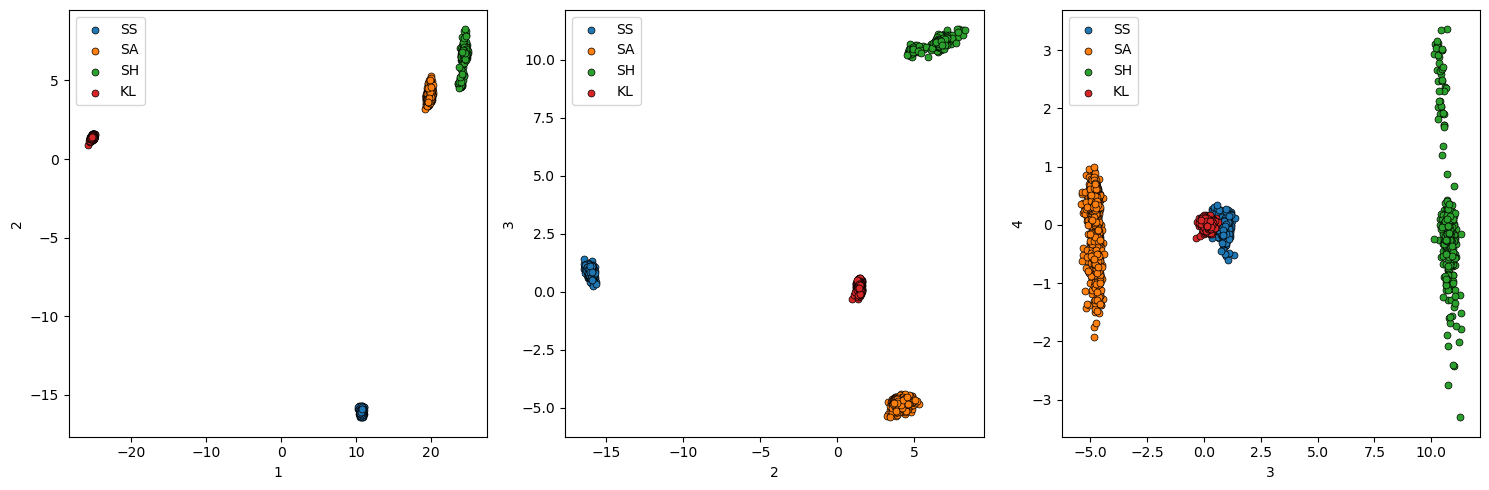

In [24]:
c, As = plot_pca(xs, [Ys_SS, Ys_SA, Ys_SH, Ys_KL], ["SS", "SA", "SH", "KL"], m=10, return_result=True)

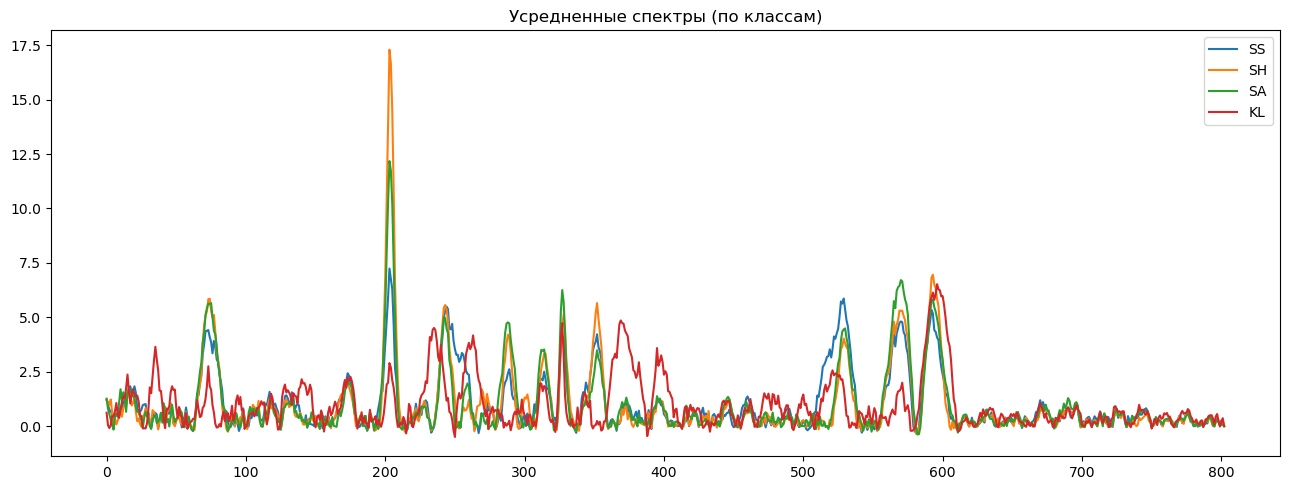

In [25]:
plt.figure(figsize=(13,5))
plt.title("Усредненные спектры (по классам)")
plt.plot(Ys_SS.mean(axis=0), label="SS")
plt.plot(Ys_SH.mean(axis=0), label="SH")
plt.plot(Ys_SA.mean(axis=0), label="SA")
plt.plot(Ys_KL.mean(axis=0), label="KL")
plt.legend()
plt.tight_layout()
plt.show()

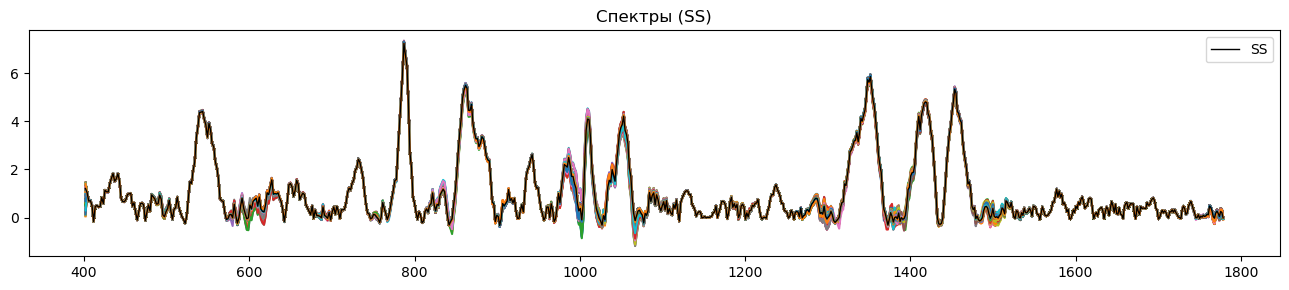

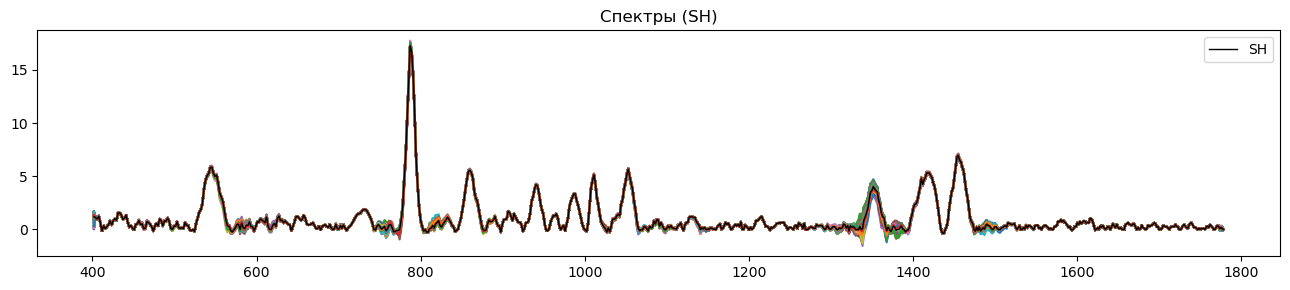

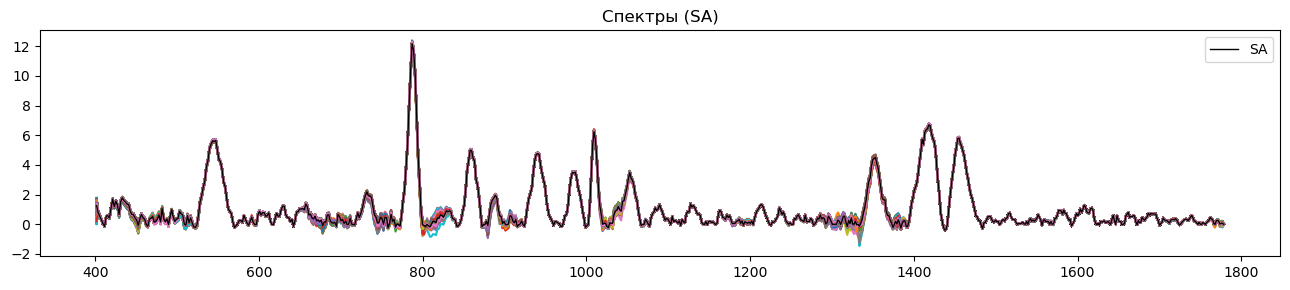

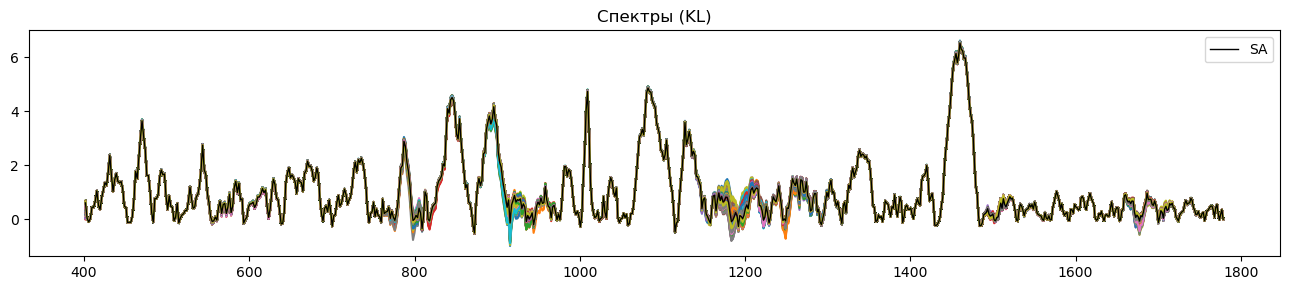

In [26]:
plt.figure(figsize=(13,3))
plt.title("Спектры (SS)")
for ys in Ys_SS:
    plt.plot(xs, ys)
plt.plot(xs, Ys_SS.mean(axis=0), lw=1.0, label="SS", color='k')
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(13,3))
plt.title("Спектры (SH)")
for ys in Ys_SH:
    plt.plot(xs, ys)
plt.plot(xs, Ys_SH.mean(axis=0), lw=1.0, label="SH", color='k')
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(13,3))
plt.title("Спектры (SA)")
for ys in Ys_SA:
    plt.plot(xs, ys)
plt.plot(xs, Ys_SA.mean(axis=0), lw=1.0, label="SA", color='k')
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(13,3))
plt.title("Спектры (KL)")
for ys in Ys_KL:
    plt.plot(xs, ys)
plt.plot(xs, Ys_KL.mean(axis=0), lw=1.0, label="SA", color='k')
plt.legend()
plt.tight_layout()
plt.show()